# Lab  2
## Recommendation system


### point 1

Выбрать датасет, подходящий для моделирования рекомендательной системы.  Хорошие 
источники данных: https://ods.ai/competitions/ (тут не все соревнования подходят, берите 
только то, что связано с рекомендательными системами, например 
https://ods.ai/competitions/vkrecsyschallengelsvd) и https://www.recsyschallenge.com/2026/ (тут 
можно подставлять любой год, начиная с 2016). Запрещено брать данные с Kaggle, так как 
по ним часто уже есть готовый EDA и baseline, а также датасет Movielens (любого размера).

In [123]:
# Я полистал на хаггин фейс датасеты. Мне приглянулась подборка из данных по стиму, а именно https://huggingface.co/datasets/frankjc2022/steam-dataset
# там есть 4 таблицы и есть ревью таблица с отзывами по играм и людям. 
from datasets import load_dataset

reviews_df = load_dataset(
    "frankjc2022/steam-dataset",
    name="reviews",
    split="train",
    cache_dir="data/hf_cache",
).to_pandas()

print(reviews_df.head())

   appid recommendationid language  \
0     10        209562818  english   
1     10        209559016  english   
2     10        209555551  english   
3     10        209554099  english   
4     10        152564493  english   

                                              review  timestamp_created  \
0                                     good and great         1763492854   
1                                      P E R F E C T         1763489346   
2  super fun game when you have an ip to same ser...         1763486120   
3                  de_dust2 smells like mothers womb         1763484767   
4  i can only wonder how good it felt to play thi...         1701327086   

   timestamp_updated  voted_up  votes_up  votes_funny  weighted_vote_score  \
0         1763492854      True         0            0                  0.5   
1         1763489346      True         0            0                  0.5   
2         1763486120      True         0            0                  0.5   
3       

In [124]:
reviews_df

,appid,recommendationid,language,review,timestamp_created,timestamp_updated,voted_up,votes_up,votes_funny,weighted_vote_score,...,author_playtime_last_two_weeks,author_playtime_at_review,author_deck_playtime_at_review,author_last_played,summary_num_reviews,summary_review_score,summary_review_score_desc,summary_total_positive,summary_total_negative,summary_total_reviews
0,10,209562818,english,good and great,1763492854,1763492854,True,0,0,0.500000,...,715,1755.0,NaN,1763492995,100,9,Overwhelmingly Positive,58570,1621,60191
1,10,209559016,english,P E R F E C T,1763489346,1763489346,True,0,0,0.500000,...,27,886.0,NaN,1763506588,100,9,Overwhelmingly Positive,58570,1621,60191
2,10,209555551,english,super fun game when you have an ip to same ser...,1763486120,1763486120,True,0,0,0.500000,...,231,819.0,NaN,1763487456,100,9,Overwhelmingly Positive,58570,1621,60191
3,10,209554099,english,de_dust2 smells like mothers womb,1763484767,1763484767,True,0,0,0.500000,...,61,116773.0,NaN,1763487412,100,9,Overwhelmingly Positive,58570,1621,60191
4,10,152564493,english,i can only wonder how good it felt to play thi...,1701327086,1763472170,True,0,0,0.500000,...,0,12101.0,NaN,1760793851,100,9,Overwhelmingly Positive,58570,1621,60191
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2631425,999860,120367786,english,Enemy On Board,1660097395,1660097395,True,0,0,0.500000,...,0,129.0,NaN,1595106545,100,6,Mostly Positive,906,380,1286
2631426,999860,120346101,english,it is basically among us with extra stuff. i j...,1660066289,1660066289,True,0,0,0.500000,...,0,255.0,NaN,1660067396,100,6,Mostly Positive,906,380,1286
2631427,999860,120189027,english,only bad thing about this game is that no one ...,1659828796,1659828796,True,0,0,0.474138,...,0,91.0,NaN,1688515141,100,6,Mostly Positive,906,380,1286
2631428,999860,119820571,english,.,1659270848,1659270848,False,0,0,0.454545,...,0,163.0,NaN,1599999226,100,6,Mostly Positive,906,380,1286


In [125]:
# из всей таблицы я оставлю часть, а именно: 
# айди автора, айди игры, голос вверх или вниз, время создания, сколько человек поиграл в игру, и сколько автор сделал обзоров на игры.
# не совсем понял, что в таблице значит rec...id 
# select
#  count(*) as total_rows,
#  count(distinct recommendationid) as unique_ids
# from reviews;
# посмтрел на хаггинг фейс - все уникальны, поэтому особо акцентировать внимание на этом не буду.
keep = ["author_steamid", "appid", "voted_up", "timestamp_created", "author_playtime_at_review", "author_num_reviews"]

df = reviews_df[keep].copy()
del reviews_df

df

,author_steamid,appid,voted_up,timestamp_created,author_playtime_at_review,author_num_reviews
0,76561198981260656,10,True,1763492854,1755.0,1
1,76561198856675958,10,True,1763489346,886.0,6
2,76561199139375042,10,True,1763486120,819.0,2
3,76561198000772249,10,True,1763484767,116773.0,3
4,76561199550130403,10,True,1701327086,12101.0,27
...,...,...,...,...,...,...
2631425,76561199011638623,999860,True,1660097395,129.0,23
2631426,76561199141005147,999860,True,1660066289,255.0,1
2631427,76561199153507428,999860,True,1659828796,91.0,24
2631428,76561198218406219,999860,False,1659270848,163.0,26


### point 2

Сделать разведочный анализ данных (EDA), то есть описать исходные данные, а также посчитать статистические показатели, построить визуализации и дать им интерпретацию, подготовить отчёт по качеству данных (пропуски, дубли, выбросы). Четко выделить целевую переменную - “что именно рекомендуем?” При необходимости предобработать данные. Сделать выводы. 

In [126]:
n_users = df.author_steamid.nunique()
n_items = df.appid.nunique()
n_reviews = len(df)

sparsity = 1 - n_reviews / (n_users * n_items)

print(f"users: {n_users:,}")
print(f"items: {n_items:,}")
print(f"reviews: {n_reviews:,}")
print(f"sparsity: {sparsity:.5%}")

del n_users, n_items, n_reviews, sparsity

users: 1,336,110
items: 44,517
reviews: 2,631,430
sparsity: 99.99558%


In [127]:
# Что мы тут видим? у нас 2,6 млн отзывов и 1,3 млн ребят, где игр 44 тысячи. Ну и если посмотреть соот. пользователь и игра 1 336 110 * 44 517 = +- 59,5 то можно понять, что у нас всего 0,00004 заполненных клеток.

In [128]:
missing = df.isna().sum()
missing_pct = missing / len(df)

for col in df.columns:
    print(f"{col}: {missing[col]:,} ({missing_pct[col]:.5%})")

del missing, missing_pct, col

author_steamid: 0 (0.00000%)
appid: 0 (0.00000%)
voted_up: 0 (0.00000%)
timestamp_created: 0 (0.00000%)
author_playtime_at_review: 3,664 (0.13924%)
author_num_reviews: 0 (0.00000%)


In [129]:
# у нас есть немного пропусков в наигранном времении ребят, поэтому уберу их; также позже уберу отзывы с временем меньше 2 часов,
# потому что сам пользуюсь steam и знаю, что там можно вернуть деньги за игру, когда наиграл меньше 2 часов и бывали случаи, когда люди покупали и писали плохой отзыв чтобы испортить статистику и опустить в рекомендациях и делали возврат.
# считаю такую статистику не показательной, потому что очень много хаотичности на отзывах 2 часа из-за системы возвратов.
# Эти моменты уберу раньше, потому что без них eda будет не в ту сторону.
df = df.dropna(subset=["author_playtime_at_review"]).copy()

In [130]:
threshold = 120
n_short = (df.author_playtime_at_review < threshold).sum()
proportion = n_short / len(df)
print(f"short reviews (< 2h): {n_short:,} ({proportion:.5%})")

short reviews (< 2h): 859,442 (32.70618%)


In [131]:
# доля конечно большая, но я все равно это сделаю.
df = df[df.author_playtime_at_review >= threshold].copy()

del threshold, n_short, proportion

In [132]:
pair = ["author_steamid", "appid"]

dup_mask = df.duplicated(pair, keep=False) 
n_extra = df.duplicated(pair).sum()

print(f"all duplicates: {dup_mask.sum():,}")
print(f"how many del to set only 1 row in dataset: {n_extra:,}")

del pair, dup_mask, n_extra

all duplicates: 12
how many del to set only 1 row in dataset: 7


In [133]:
# Всего пару строчек, ничего страшного уберем выбросы, оставим самые последние
df = df.sort_values("timestamp_created").drop_duplicates(["author_steamid", "appid"], keep="last").copy()

In [134]:
per_user = df.groupby("author_steamid").size()
print(per_user.describe().to_string())

for k in [1, 2, 3, 5, 10, 20]:
    n = (per_user >= k).sum()
    per = n / len(per_user)
    print(f"{k}: {n:,} users ({per:.2%})")

del k, n, per_user, per
# Сейчас картина не очень классная. У нас всего 21% пользователей имеет больше 1 отзыва у себя.

count    1.018799e+06
mean     1.735688e+00
std      9.049130e+00
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      5.325000e+03
1: 1,018,799 users (100.00%)
2: 223,930 users (21.98%)
3: 103,633 users (10.17%)
5: 43,137 users (4.23%)
10: 14,032 users (1.38%)
20: 4,628 users (0.45%)


In [135]:
per_game = df.groupby("appid").size()
print(per_game.describe().to_string())

max_n = per_game.max()
n_capped = (per_game == max_n).sum()

print(f"max reviews per game: {max_n:,}")
print(f"games with the max: {n_capped:,} ({n_capped / len(per_game):.2%})")

del max_n, n_capped

# тут можно сказать только то, что человек ограничил кол-во отызвов на игру до 100.

count    41681.000000
mean        42.425014
std         34.456874
min          1.000000
25%          8.000000
50%         35.000000
75%         78.000000
max        100.000000
max reviews per game: 100
games with the max: 187 (0.45%)


In [136]:
# проверим так ли это на всякий и уберу меньше двух часов потому что это 30 процентов.
game_total = load_dataset("frankjc2022/steam-dataset", name="reviews", split="train", cache_dir="data/hf_cache").select_columns(["appid", "summary_total_reviews", "author_playtime_at_review"]).to_pandas()
game_total = game_total[game_total.author_playtime_at_review >= 120].copy()
print(len(game_total))

game_total = game_total.groupby("appid")["summary_total_reviews"].first()

stats = game_total.describe(percentiles=[.25, .5, .75, .9, .99])

for name, value in stats.items():
    print(f"{name:>6}: {value:>12,.0f}")

del name, value, stats, game_total

# ну вот да. У нас лишь половина имеет около 75 отзывов, при этом 75 процентов не больше 317 отзывов. То есть в основном больше 100 точно есть.

1768324
 count:       41,681
  mean:        1,748
   std:       19,411
   min:            1
   25%:           22
   50%:           75
   75%:          317
   90%:        1,552
   99%:       28,915
   max:    2,437,395


In [137]:
game_total = load_dataset("frankjc2022/steam-dataset", name="reviews", split="train", cache_dir="data/hf_cache").select_columns(["appid", "summary_total_reviews", "author_playtime_at_review"]).to_pandas()
game_total = game_total.groupby("appid")["summary_total_reviews"].first()

stats = game_total.describe(percentiles=[.25, .5, .75, .9, .99])

for name, value in stats.items():
    print(f"{name:>6}: {value:>12,.0f}")

del name, value, stats, game_total
# Без чистки. У нас лишь половина имеет около 63 отзывов, при этом 75 процентов не больше 279 отзывов. То есть в основном больше 100 точно есть.

 count:       44,517
  mean:        1,637
   std:       18,787
   min:            1
   25%:           17
   50%:           63
   75%:          279
   90%:        1,391
   99%:       26,844
   max:    2,437,395


In [138]:
for k in [10, 20, 50, 100]:
    n = (per_game >= k).sum()
    per = n / len(per_game)
    print(f"{k}: {n:,} games ({per:.2%})")

del k, n, per 

# Получается у 30 тысяч игр сейчас не меньше 10 отызвов.
# Думаю буду смотреть так, чтобы в конечном итоге были игры и пользователи с большим кол-во отзывов и у людей не меньше 2 отзывов может возьму больше. Тут целится будем в 20 и может больше.

10: 30,367 games (72.86%)
20: 25,464 games (61.09%)
50: 17,517 games (42.03%)
100: 187 games (0.45%)


In [139]:
# так теперь наша цель смотреть на игры с положительной рекомендацией в steam. Есть всего два варианта отзыва на игру - это положительный отзыв(то есть рекомендую) или отрицательный отзыв(не рекомендуем).


pos_share = df["voted_up"].mean()
print(f"positive: {pos_share:.2%}")
print(f"negative: {1 - pos_share:.2%}")

del pos_share

# Здесь мы видим соотношение 4:1 данные сильно перекошены в сторону положительных отызвов

positive: 81.75%
negative: 18.25%


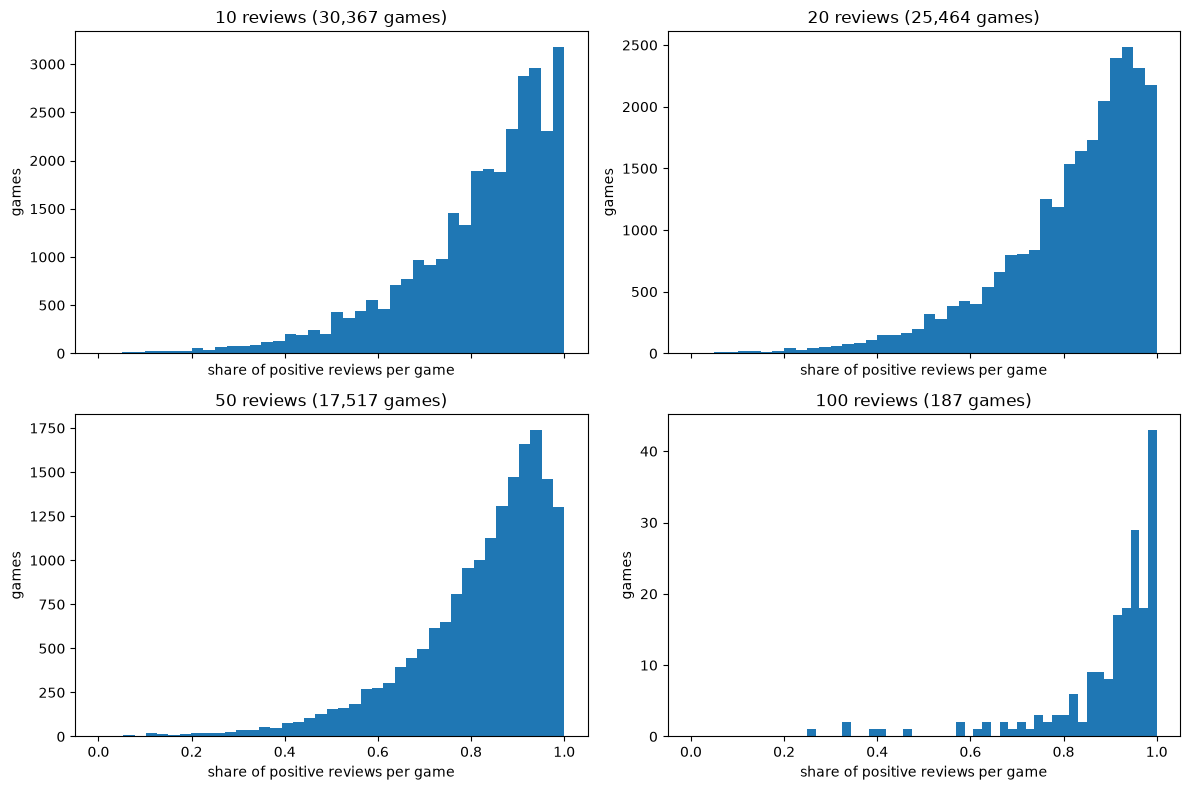

In [140]:
import matplotlib.pyplot as plt

game_all = df.groupby("appid")["voted_up"].agg(["mean", "size"])

thresholds = [10, 20, 50, 100]
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)

for ax, k in zip(axes.flat, thresholds):
    part = game_all[game_all["size"] >= k]
    ax.hist(part["mean"], bins=40)
    ax.set_title(f"{k} reviews ({len(part):,} games)")
    ax.set_xlabel("share of positive reviews per game")
    ax.set_ylabel("games")

plt.tight_layout()
plt.show()

del game_all, thresholds, fig, axes, ax, k, part

# тут мы видим, что порог на отзывы не влияет на качество отзывов по играм.

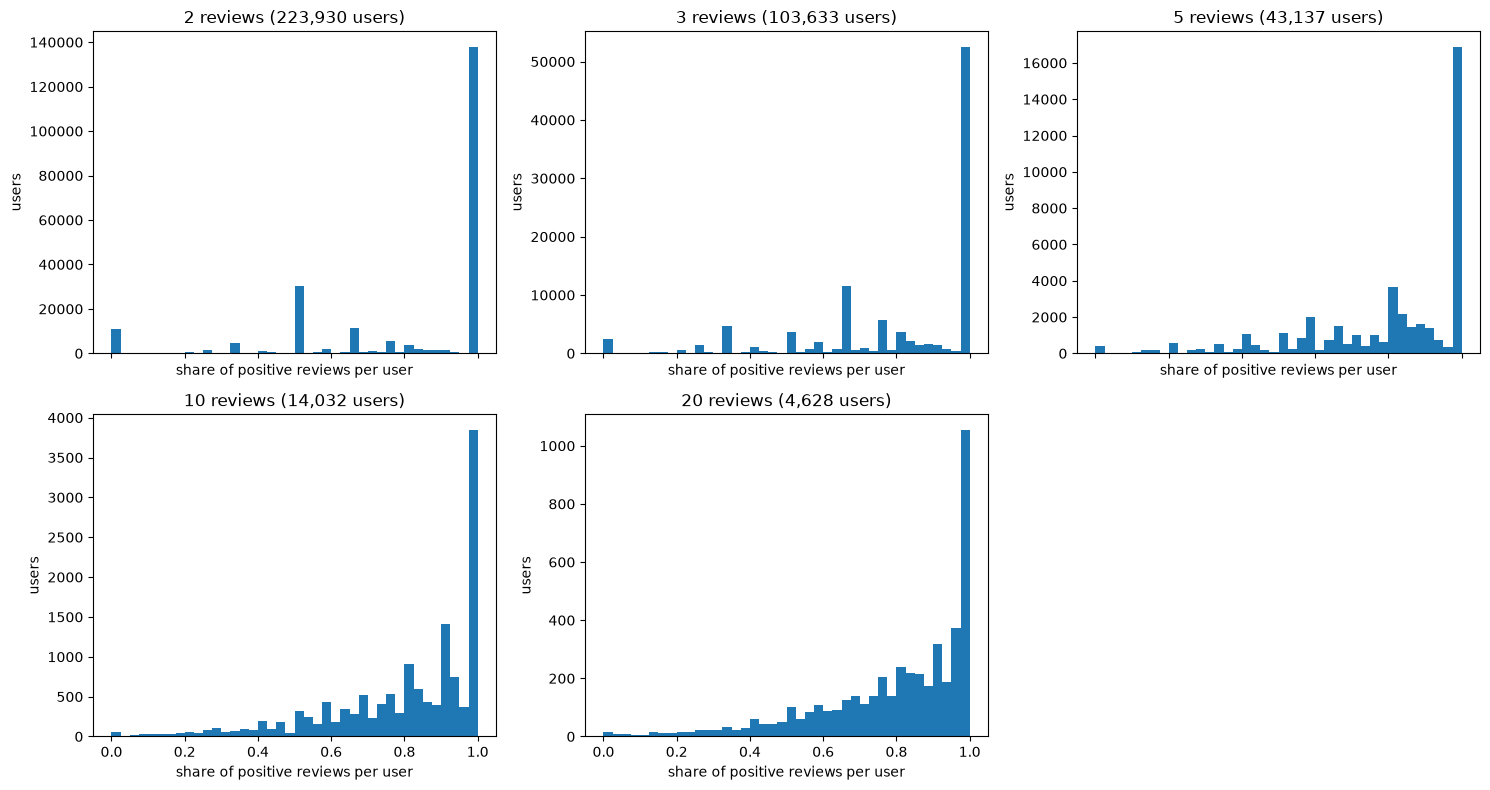

In [141]:
user_all = df.groupby("author_steamid")["voted_up"].agg(["mean", "size"])

thresholds = [2, 3, 5, 10, 20]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)

for ax, k in zip(axes.flat, thresholds):
    part = user_all[user_all["size"] >= k]
    ax.hist(part["mean"], bins=40)
    ax.set_title(f"{k} reviews ({len(part):,} users)")
    ax.set_xlabel("share of positive reviews per user")
    ax.set_ylabel("users")

axes.flat[-1].axis("off") 

plt.tight_layout()
plt.show()


del user_all, thresholds, fig, axes, ax, k, part 

# тут мы видим, что все ребята в основном хвалят игры и пики в центре и на краях это скорее ограничение датасета, чем какая-то закономерность. Думаю в основном оно выглядит, как на последнем графике.
# поскольку отзывы в основном положительные в обучение будем брать именно их, а то, что не понравилось брать не будем.

count    1768317.0
mean          53.9
std          450.8
min            2.0
25%            4.2
50%            8.4
75%           21.4
max        74977.2


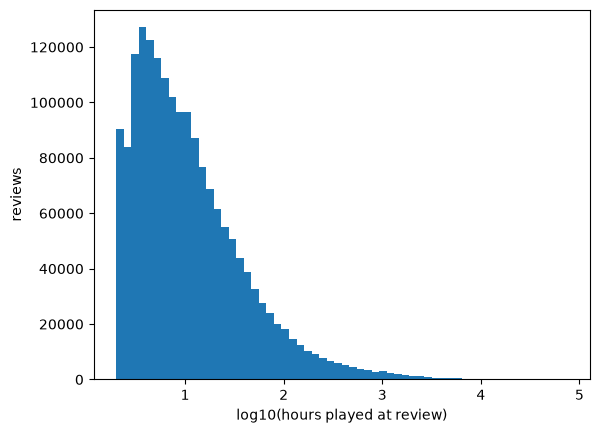

In [142]:
import numpy as np

hours = df["author_playtime_at_review"] / 60
print(hours.describe().round(1).to_string())

plt.hist(np.log10(hours), bins=60)
plt.xlabel("log10(hours played at review)")
plt.ylabel("reviews")
plt.show()

del hours

# пришлось взять логарифм, потому что график не очень удобный был из-за от 2 часов до 75 тысяч.
# видно мой фильтр от двух часов и что в среднем 8 часов ребята играют. И это скопление начинается от 5 часов.


In [143]:
# Тут думаю чуть больше надо посмотреть.
hours = df["author_playtime_at_review"] / 60

for h in [100, 1000, 5000, 10000, 20000]:
    n = (hours > h).sum()
    print(f"{h:>6,} h: {n:,} reviews ({n / len(hours):.3%})")

del hours, h, n
# каких-то явных проблем тут нет. Изначально меня смутило время 74 тысячи часов в игре, но мне кажется 
# людей, которые столько играют не существует. Но с другой стороны, если человек накрутил время или не 
# выключал компьютер, то по такой логике он мог это сделать и через 5 часов игры, и через 10. Поэтому 
# смотреть по часам нет особого смысла. Думаю даже отзывы с 5 тысяча будут куда релевантее, потому что 
# человек чуть ли не жизнь отдал этой игре.


   100 h: 114,512 reviews (6.476%)
 1,000 h: 14,691 reviews (0.831%)
 5,000 h: 1,896 reviews (0.107%)
10,000 h: 656 reviews (0.037%)
20,000 h: 146 reviews (0.008%)


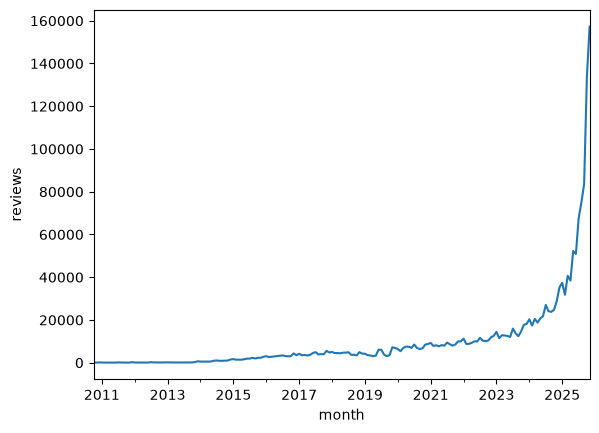

In [144]:
# Пока думал насчет времени думал, что будет релевантнее смотреть. По опыту популярных игр, могу сказать, что в день выпуска может быть берст отзывов, а также может быть такое, что следующие отзывы уже будут после исправлений ошибок в игре. Поэтому это все равно посмотрим в нашем датасете.
import pandas as pd

dt = pd.to_datetime(df["timestamp_created"], unit="s")
dt.dt.to_period("M").value_counts().sort_index().plot()
plt.xlabel("month")
plt.ylabel("reviews")
plt.show()

del dt

# тут у нас динамика по месяцам. Видно, что в некоторых месяцах выходят популярные релизы и есть скочки небольшие, но в основной массе отзывы растут ожидаемо. Потому что датасет относительно свежий и автору попадались новые отызывы по популярным играм. Вспомним еще что он ограничил до 100 отызывов на игру.

In [145]:
tmp = df[["author_steamid", "timestamp_created"]].copy()
tmp["day"] = pd.to_datetime(tmp["timestamp_created"], unit="s").dt.date

g = tmp.groupby("author_steamid").agg(n=("day", "size"), days=("day", "nunique"))
g = g[g["n"] >= 5]

same_day = (g["days"] == 1).mean()
print(f"users with >=5 reviews: {len(g):,}")
print(f"all reviews on a single day: {same_day:.2%}")
print((g["n"] / g["days"]).describe().round(2).to_string())

del tmp, g, same_day

# Супер! ботов немного в основном человек пишет не больше отзыва за день.

users with >=5 reviews: 43,137
all reviews on a single day: 1.92%
count    43137.00
mean         1.43
std          1.90
min          1.00
25%          1.00
50%          1.00
75%          1.20
max         84.00


In [146]:
per_user = df.groupby("author_steamid").size()

for q in [0.5, 0.9, 0.99, 0.999]:
    print(f"{q:.1%} quantile: {per_user.quantile(q):,.0f} reviews")
print()

for k in [50, 100, 200, 300, 500, 1000]:
    n = (per_user > k).sum()
    r = per_user[per_user > k].sum()
    print(f"{k:>5,} reviews: {n:,} users, {r:,} reviews ({r / len(df):.2%} of all)")

del per_user, q, k, n, r

50.0% quantile: 1 reviews
90.0% quantile: 3 reviews
99.0% quantile: 12 reviews
99.9% quantile: 52 reviews

   50 reviews: 1,061 users, 122,001 reviews (6.90% of all)
  100 reviews: 287 users, 68,957 reviews (3.90% of all)
  200 reviews: 74 users, 40,039 reviews (2.26% of all)
  300 reviews: 32 users, 30,051 reviews (1.70% of all)
  500 reviews: 18 users, 25,190 reviews (1.42% of all)
1,000 reviews: 8 users, 19,240 reviews (1.09% of all)


In [147]:
tmp = df[["author_steamid", "voted_up", "timestamp_created"]].copy()
tmp["day"] = pd.to_datetime(tmp["timestamp_created"], unit="s").dt.date

top = tmp.groupby("author_steamid").agg(n = ("voted_up", "size"), pos_share = ("voted_up", "mean"), days = ("day", "nunique"))
top["per_day"] = top["n"] / top["days"]
top = top[top["n"] > 400].sort_values("n", ascending=False)

print(top.round(2).to_string())

del tmp, top

                      n  pos_share  days  per_day
author_steamid                                   
76561198367471798  5325       0.98   168    31.70
76561198036629241  3423       1.00   201    17.03
76561199011650843  3262       1.00    49    66.57
76561198030784015  2523       0.01  1262     2.00
76561199010042150  1534       1.00    33    46.48
76561198027267313  1090       0.01   345     3.16
76561198025731804  1052       1.00   605     1.74
76561198010646448  1031       0.01    25    41.24
76561198082649849   771       0.29   296     2.60
76561197970539229   719       0.81   173     4.16
76561197970602587   691       0.21   572     1.21
76561198094803808   601       0.16   471     1.28
76561198000998015   578       0.63   211     2.74
76561197970193418   562       1.00   200     2.81
76561198327205690   509       1.00    78     6.53
76561197960373660   508       0.82    44    11.55
76561198063952731   508       0.61   343     1.48
76561198376781921   503       1.00   329     1.53


In [148]:
# 76561198010646448  1031       0.01    25    41.24 - бот, который занижал оценки. ДА уж
# в целом хорошо на самом деле. Я посмотрел на 200, 300 и там действительно много коллекционеров. Вот уже с 500 отзывов начинаются боты. Таблицу вывел выше от 500.
# 76561198030784015  2523       0.01  1262     2.00
# Сложно представить, что кто-то может делать под два отзыва на протяжение 3 лет (дни когда писались отызвы, не обязательно подряд), когда игры в среднем по 5+ часов. Так и еще все отзывы отрицательные. Я бы убрал пользователей с 500+ отзывами даже если подрежу коллекционера или блогера, потому что тут преимущественно боты.

In [149]:
# чистим теперь
data = df[df.voted_up]

In [150]:
total = df.groupby("author_steamid")["appid"].transform("size")
heavy = total.loc[data.index] > 500
data = data[~heavy]

In [151]:
round_no = 0
while True:
    n = len(data)
    data = data[data.groupby("author_steamid")["appid"].transform("size") >= 5]
    data = data[data.groupby("appid")["author_steamid"].transform("size") >= 10]
    round_no += 1
    if len(data) == n:
        break

del round_no, n

In [152]:
u = data["author_steamid"].nunique()
i = data["appid"].nunique()
sparsity = 1 - len(data) / (u * i)

print(f"rows: {len(data):,}")
print(f"users: {u:,}")
print(f"items: {i:,}")
print(f"sparsity: {sparsity:.4%}")
print(f"avg items per user: {len(data) / u:.1f}")

del u, i

# Так в общем я посмотрел при 5/20 отзыв пользователь/отзывов положительных на игру - было очень мало данных.
# rows: 23,609
# users: 1,402
# items: 587
# sparsity: 97.1313%
# avg items per user: 16.8

# при 3/20 
# rows: 145,418
# users: 20,960
# items: 4,691
# sparsity: 99.8521%
# Но три игры на человека слишком мало, поэтому я попробовал убрать 20 позитивных отзывов на 10, и думаю это логично учитывая ограничение 100 отзывов на игру. и 10 тысяч уже хорошая выборка.

rows: 208,683
users: 17,946
items: 10,641
sparsity: 99.8907%
avg items per user: 11.6


### part of point 5

Выделить обучающую и тестовую выборки. На тестовой выборки вычислить значения выбранных метрик качества. Сравнить методы и дать интерпретацию результатов по полученным метрикам.


In [153]:
# подводя итоги по 2 пункту я делаю следующее
# предобработал выборку от дублей, нескольких изменений отзывов, отзывов без активных часов игры, ботов накрутчиков, у которых не типичное поведение в виде 500 отзывов, где много во один день или больше 1 в особенности, и упростил ограничение положительных отзывов до 10 вместо более показательных 20 на игру и больше, в следствии 100 отзывов ограничения на игру. Убрал очень хаотичную выборку отзывов до 2 часов от пользователей, потому что они очень высокорисковые в следствии политики платформы. Спокойно могла быть накрутка отзывов и возвращение товара.
# есть пользователь author_steamid 17,946 ребят 
# игры которые рекомендуем appid 10 641 игр
# оценка понравлось voted_up true
# по истории из игр говорим следующие, которые должны понравится 
# также не учитываем игры 2026 года, выборка заканчивается на 2025 году и не учитываем игры вышедшие раньше 2011 года.

In [154]:
# Так вижу что в поинте 5 у нас делается выборка для обучения и само обучение. Но подготовлю выборку я чуть раньше. Во 2 point ниже. Идея такая делаем так: Коля играл в а б с д e, где а б с д раньше вермени e и именное е самая поздняя игра коли должна предугадать наша система.

data = data.sort_values(["author_steamid", "timestamp_created", "appid"])
pos_from_end = data.groupby("author_steamid").cumcount(ascending=False)

test = data[pos_from_end == 0]
train = data[pos_from_end > 0]

unseen = ~test["appid"].isin(train["appid"].unique())

print(f"train: {len(train):,} rows, {train['author_steamid'].nunique():,} users, {train['appid'].nunique():,} items")
print(f"test:  {len(test):,} rows, {test['author_steamid'].nunique():,} users, {test['appid'].nunique():,} items")
print()
print(f"min train items per user: {train.groupby('author_steamid').size().min()}")
print(f"test items missing in train: {unseen.sum():,} ({unseen.mean():.3%})")

del pos_from_end, unseen

# У нас есть пару отзывов новинок, потому что у нескольких авторов к каким-то играм получились отзывы, которые были самыми последними.
# Разница между train играми и test играми в том, что у нас игры не пересеклись и это нормально.

train: 190,737 rows, 17,946 users, 10,639 items
test:  17,946 rows, 17,946 users, 7,210 items

min train items per user: 4
test items missing in train: 34 (0.189%)


In [155]:
from scipy.sparse import csr_matrix

u = pd.Categorical(train["author_steamid"])
i = pd.Categorical(train["appid"])

user_ids = u.categories.to_numpy() 
item_ids = i.categories.to_numpy()

user_index = { u: k for k, u in enumerate(user_ids) }
item_index = { a: k for k, a in enumerate(item_ids) }

n_users, n_items = len(user_ids), len(item_ids)
X = csr_matrix(
    (np.ones(len(train)), (u.codes, i.codes)),
    shape = (n_users, n_items),
)

t_u = test["author_steamid"].map(user_index)
t_i = test["appid"].map(item_index)

ok = t_i.notna() # в том плане, что если игра новая у нас может не быть в тренировочной выборке

X_test = csr_matrix(
    (np.ones(ok.sum()), (t_u[ok].astype(int), t_i[ok].astype(int))),
    shape = (n_users, n_items),
)

print(f"X: {X.shape}, nnz = {X.nnz:,}")
print(f"X_test: {X_test.shape}, nnz = {X_test.nnz:,}")

del u, i, t_u, t_i, ok

X: (17946, 10639), nnz = 190,737
X_test: (17946, 10639), nnz = 17,912


In [156]:
# надо закрыть дырку и сделать так, чтобы игр, которых нет будет считаться -1. То есть мы промахнулись.
# Или другими словами: для каждого пользователя храним номер его тестовой игры, если тестовой игры нет в обучении/для нее нет столбца в матрице, то пишем -1. Номера идут 0, 1, 2, 3 => промах, потому что -1 невозможен по индексам.
test_item = np.full(n_users, -1)
rows = np.where(np.diff(X_test.indptr) == 1)[0]
test_item[rows] = X_test.indices

del rows

In [157]:
K = 10 # наш топ  
# Тут теперь важно сделать следующее:
# матрица выглядит так 
# /         игра 0 игра 1 игра 2
# человек 0   1     0       0
# мы берем складываем единицы по столбцам матрицы. 1 - Значит положительный отзыв, 0 - нет инфы.
# так делается для каждой игры и потом делаем из этого питоновский список вместо numpy.
item_pop = np.asarray(X.sum(axis = 0)).ravel() 
# тут просто считается сколько пол отзывов всего об игре от общего числа пользователей. Помним, что только один отзыв от человека на игру в датасете.
item_prob = item_pop / n_users 

In [158]:
# Теперь напишем саму функцию рекомендации, которая будет принимать методы формирования рекомендаций.
# fn - методы формирования рекомендаций
# k - сколько рекомендаций, он в ячейке выше.
def recommend(fn, k = K):
    idx = np.arange(n_users)                            
    sc = np.array(fn(idx), dtype = np.float32)
    r, c = X.nonzero()                        
    # тут может быть не очень очевидно, но идея такая: 
    # /         игра 0 игра 1 игра 2
    # человек 0  0.2    0.1    0.1 <- как пример. В зависимости от функции может быть другое...
    #  такая матрица хранится в sc, а тут мы получаем список индексов людей "r",
    #  и соответсвующий список индексов "c" игр для этих людей, которые оставили положительный отзыв. 
    # это делается для того, чтобы убрать игры, которые пользователь уже прошел,
    # и составить ему список рекомендаций на основе того, во что он еще не играл. 
    sc[r, c] = -np.inf
    
    # тут по пользователю сортируем от лудшей игре к худшей. Минус это особенность нумпая, чтобы порядок был по убыванию  
    # ну и просто потом берем топ k игр для каждого пользователя.
    res = np.argsort(-sc, axis = 1)[:, :k] 
    
    return res  

### point 4
Выбрать не менее четырех метрик оценки качества рекомендаций. Рассчитать их. Нужно выбрать хотя бы одну метрику, учитывающую качество ранжирования. Нужно выбрать хотя бы одну специфическую для рекомендательных систем метрику (новизна, разнообразие, serendipity/неожиданность).


Обозначения: 

* $U$ - множество пользователей,
* $I$ - каталог игр,
* $R_u$ - список из $K$ рекомендаций пользователю $u$,
* $t_u$ - его тестовая игра, 
* $\mathrm{rank}_u$ - её позиция в списке (с 1).

Recall@K - доля пользователей, у которых тестовая игра попала в топ-K.
Показывает, как часто система угадывает следующую игру пользователя.
Чем выше, тем лучше. Так как тестовая игра у каждого одна.

$$
\mathrm{Recall@}K = \frac{1}{|U|} \sum_{u \in U} \mathbb{1}\left[t_u \in R_u\right]
$$


NDCG@K - метрика ранжирования: попадание на 1 месте будет 1, на 2 например 0.62, ... на 10-м например 0.21. Как Recall, но с учётом места в списке.

$$
\mathrm{NDCG@}K = \frac{1}{|U|} \sum_{u \in U} \frac{\mathbb{1}\left[t_u \in R_u\right]}{\log_2\left(\mathrm{rank}_u + 1\right)}
$$

MRR@K - метрика ранжирования: среднее значение 1/позиция найденной игры.
Показывает, насколько высоко в списке в среднем стоит угаданная игра.
Падает быстрее NDCG, поэтому сильнее наказывает за каждое место ниже первого.

$$
\mathrm{MRR@}K = \frac{1}{|U|} \sum_{u \in U} \frac{\mathbb{1}\left[t_u \in R_u\right]}{\mathrm{rank}_u}
$$

Coverage@K - какая доля каталога вообще попадает в рекомендации. Низкое значение значит, что система рекомендует всем одно и то же.

$$
\mathrm{Coverage@}K = \frac{\left|\bigcup_{u \in U} R_u\right|}{|I|}
$$

Novelty@K - cредняя редкость рекомендованных игр. Чем меньшая доля пользователей оценила игру в обучении, тем выше её вклад.
Высокое значение значит, что система предлагает менее очевидные игры, низкое значит, что рекомендуются хиты.

$$
\mathrm{Novelty@}K = \frac{1}{|U| \cdot K} \sum_{u \in U} \sum_{i \in R_u} \left(-\log_2 p(i)\right), \qquad p(i) = \frac{|\{u : i \in \text{train}_u\}|}{|U|}
$$


Из учебных материалов:

Концептуальная эволюция метрик
Связка четырех основных метрик выстраивает логичный маршрут пользовательского запроса:

Precision@K: «Какая доля из показанных результатов качественная?» (оценка чистоты окна).

MRR: «Насколько быстро пользователь наткнется на первое рабочее решение?» (оценка скорости навигации).

MAP: «Насколько компактно все существующие в базе ответы собраны к верху выдачи?» (оценка полноты ранжирования бинарных списков).

nDCG@K: «Насколько структура выдачи соответствует идеальному убыванию полезности с учетом градаций качества?» (оценка многоуровневого ранжирования).



In [159]:
def evaluate(R):
    U, I = n_users, n_items # очевидно кол-во ребят игр соот.
    t_u = test_item  # тестовая матрица
    p = item_prob  # уже рассказывал выше вычисления это константа  

    match = (R == t_u[:, None]) # тут если -1 промах, то вся выборка будет возвращать false. Индекса -1 не сущ.      
    hit = match.any(axis = 1) # 1[t_u in R_u]
    rank = match.argmax(axis = 1) + 1

    return {
        f"Recall@{K}" : hit.sum() / U,
        f"NDCG@{K}" : (hit / np.log2(rank + 1)).sum() / U,
        f"MRR@{K}" : (hit / rank).sum() / U,
        f"Coverage@{K}": len(np.unique(R)) / I,
        f"Novelty@{K}":  (-np.log2(p[R])).sum() / (U * K),
    }

Дальше также буду объединять 5  пункт с 3 и сразу считать.

### point 3

Выбрать минимум три метода формирования рекомендации. Реализовать их. Рекомендуемые методы: 1) MostPop, 2) UserKNN или ItemKNN, 3) SLIM или EASE, 4) версии SVD или ALS. При выборе методов старайтесь брать методы из разных семейств.


Зачем нужны простые бейзлайны:
Санитарный контроль (Sanity Check): любая сложная персонализированная модель обязана доказать, что превосходит алгоритмы без обучаемых параметров.
Защита от «Холодного старта» (Cold Start Fallback): когда в систему приходит новый пользователь без истории, коллаборативная модель возвращает пустоту. Сервис обязан выдать самый надежный неперсонализированный список.
Контроль популярного смещения (Popularity Bias): если модель просто выучивает распределение популярности каталога, она формально показывает высокий HitRate, но не создает персональной ценности для пользователя.

In [160]:
def mostpop_scores(idx):
    table = []
    for _ in idx:                
        table.append(item_pop)  
    return np.array(table)

recs_pop = recommend(mostpop_scores)
res_pop = evaluate(recs_pop)

for name, value in res_pop.items():
    print(f"{name:14s} {value:.7f}")

del name, value

# Recall@10 0.0001114 => попал всего 2 раза из 17 946. Получилось так, что система даже не угадывает игру, а дает результат хуже случайного.
# NDCG@10 и MRR@10 0.0000366 и 0.0000155 => точно также попаданий почти не было.
# Coverage@10 0.0039477 и Novelty@10 7.4921373 => Каждому рекомендуют почти один и тот же набор. Или же самые популярные игры.
# Думаю такая проблема вылезла просто потому, что у меня лимит в 100 отзывов на игру и этого было не достаточно. 
# Как это работает: 
#              a  b  c  d
# item_pop = [10, 7, 3, 2]
# допустим у меня a старая игра. Нет ни одного нового обзора от человека. 
# тогда в результате мое деление на train и test по последним обзорам приведет к тому, что у меня тестовый сценарий будет допустим обзор из c или любой другой игры, но не а, но а будет самой восстребованной и будет рекомендовать ее. За исключением ситуаций, когда игра уже пройдена. Думаю тогда и были те самые удачные  случаи.

Recall@10      0.0001114
NDCG@10        0.0000366
MRR@10         0.0000155
Coverage@10    0.0039477
Novelty@10     7.4921373


In [161]:
from scipy.sparse import diags

# Идея такая: 
#          игра 0 игра 1 игра 2
# чел 0     1      1       0
# чел 1     1      1       1
# чел 2     0      0       1
#          игра 0 игра 1 игра 2
# игра 0     0      1       0.5
# игра 1     1      0       0.5
# игра 2     0.5    0.5       0
# игры 0 и 1 оценивали чел 0 и чел 1 поэтому сходство 1
# игры 0 и 2 делит только чел 1 поэтому сходство 0.5

# поскольку KNN добавил распил после k. к как примере возьму равное ста. Только сто ближайших соседей. 
# идея простая соседи остальные ноль.
def keep_nearest_neighbors(S, k):
    game_ids, neighbor_ids, similarities = [], [], []
    for game in range(S.shape[0]):
        row = S[game].toarray().ravel()
        nearest = np.argpartition(-row, k)[: k]
        game_ids += [game] * k
        neighbor_ids += list(nearest)
        similarities += list(row[nearest])

    S_k = csr_matrix((similarities, (game_ids, neighbor_ids)), shape = S.shape)
    S_k.eliminate_zeros()
    return S_k

# Сколько людей оценили обe игры 
C = (X.T @ X).tocsr()
# корень нужен для того, чтобы самую хитовую игру спустить с небес, 
# то есть есть три игры все связанны A B C. B оценили все поэтому а A C нет - ребят было меньше. Тогда коэф у А С будет больше B
D = diags(1 / np.sqrt(item_pop))
S = (D @ C @ D).tocsr()                 

S.setdiag(0) # игра не похожа сама на себя 
S.eliminate_zeros()
S_k = keep_nearest_neighbors(S, k=100)  

def itemknn_scores(idx):
    return (X[idx] @ S_k).toarray()      

recs_knn = recommend(itemknn_scores)
res_knn = evaluate(recs_knn)

for name, value in res_knn.items():
    print(f"{name:14s} {value:.4f}")

del C, D, name, value


# Что имеем в итоге? Для каждой игры взяли 100 соседей и наилучшая игра для человека эта та игра которая схожа с другими играми которые он оценил
# Recall@10, теперь улучшился в кучу раз по сравнению с mostpop_scores, как и все остальные характеристики. Но до сих пор не очень высокая, потому что в большинстве своем отзывов 5 на пользователя, если бы их было больше, то более крепкие связи образовались.
# Novelty@10 10.0631 стал больше заметно, теперь у нас все чаще попадаются редкие игры, в отличии от популярных.
# Coverage@10 = 0.938 рекомендации используют 93% каталога, а не выдают одни и теже игры как mostpop_scores.

Recall@10      0.1072
NDCG@10        0.0680
MRR@10         0.0559
Coverage@10    0.9380
Novelty@10     10.0631


In [ ]:
lam = 50 

# Идея такая: 
#          игра 0 игра 1 игра 2
# чел 0     1      1       0
# чел 1     1      1       1
# чел 2     0      0       1
G = (X.T @ X).toarray().astype(np.float32)
#          игра 0 игра 1 игра 2
# игра 0     2      2       1
# игра 1     2      2       1
# игра 2     1      1       2
# видно что игру 0 и 2 оценило два человека, но при этом они не одновременно ее оценили, поэтому тут 1 вместо двух. 
G[np.diag_indices_from(G)] += lam
#          игра 0 игра 1 игра 2
# игра 0     102      2       1
# игра 1     2      102       1
# игра 2     1      1       102
P = np.linalg.inv(G)
# B[i, j] = −P[i, j] / P[j, j]
# Тут инвретируется и убираем то, что уже оценили и игры самих себя дальше. То есть смотрим на всю картину целиком и идем уже от сущ весов.
B = P / (-np.diag(P))
B[np.diag_indices_from(B)] = 0 

def ease_scores(idx):
    return X[idx] @ B

recs_ease = recommend(ease_scores)
res_ease = evaluate(recs_ease)

for name, value in res_ease.items():
    print(f"{name:14s} {value:.4f}")

del name, value, G, P

In [121]:
lam = 20 
G = (X.T @ X).toarray().astype(np.float32)
G[np.diag_indices_from(G)] += lam
P = np.linalg.inv(G)
B = P / (-np.diag(P))
B[np.diag_indices_from(B)] = 0 

def ease_scores(idx):
    return X[idx] @ B

recs_ease = recommend(ease_scores)
res_ease = evaluate(recs_ease)

for name, value in res_ease.items():
    print(f"{name:14s} {value:.4f}")

del name, value, G, P

Recall@10      0.1118
NDCG@10        0.0698
MRR@10         0.0569
Coverage@10    0.9737
Novelty@10     9.6756


In [122]:
lam = 100 
G = (X.T @ X).toarray().astype(np.float32)
G[np.diag_indices_from(G)] += lam
P = np.linalg.inv(G)
B = P / (-np.diag(P))
B[np.diag_indices_from(B)] = 0 

def ease_scores(idx):
    return X[idx] @ B

recs_ease = recommend(ease_scores)
res_ease = evaluate(recs_ease)

for name, value in res_ease.items():
    print(f"{name:14s} {value:.4f}")

del name, value, G, P

# Я проверил на 3 значения 20 50 100 и заметил, что при lam 20 50 мы выходим на некое плато и результаты примерно одинаковые
# При 100 держимся по характеристики примерно как item knn. Но при этом aese несмотря на более лучший recall рекомендует чаще новинки чем item knn, но также гараздо меньше, чем mostpop. Больше всего мне понравлось, что при 20 у нас чуть ли не 98 процентов охват данных игр.

Recall@10      0.1094
NDCG@10        0.0680
MRR@10         0.0553
Coverage@10    0.9371
Novelty@10     9.5797


### point 6
Сформулировать предложения по улучшению качества рекомендаций. Сделать выводы.


In [109]:
# Улучшения:
# 1. Подобрать параметры на отдельной валидации (число соседей k у ItemKNN, lam у EASE). Сейчас они
#    выбраны без подбора, а значения lam сравнивались на тесте.
# 2. Попробовать давайть вес отзывам в зависимости от времени их публикации. Старее меньше весят.
# 3. Собрать больше данных без лимита в 100 отзывов на игру и добавить описание игр (теги, жанры):
#    так популярность станет различимой, а игры без истории можно будет рекомендовать.

# Вывод: персонализированные методы ItemKNN и EASE во много раз точнее MostPop.
# EASE при lam = 20-50 немного точнее ItemKNN и лучше по покрытию каталога, но
# рекомендует чуть более популярные игры (Novelty 9.6-9.7 против 10.06). Качество EASE
# зависит от lam и выходит на плато при lam = 20-50. Разница между ItemKNN и EASE небольшая
# и статистически не проверялась.
# Не смотря на то, что датасет имел большое количество отзывов аккаунтов одиночек и 30% отызвов меньше двух часов,
# и жесткое ограничение в 100 отзывов на игру мне все равно понравилось с ним работать, но кажется для рекомендательной системы
# надо было учесть веса времени отзывов и убрать ограничение. 